# DS02 · Ağaç derinliği

Aynı 256/256 pencereler ve 36 girdiyle ağaç derinliği uçuş sonu RUL
tahminini iyileştiriyor mu? Colab çalışma zamanında hücreleri sırayla
çalıştırın. Yalnızca DS02 dev verisi kullanılır.

In [ ]:
import hashlib
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display
from xgboost import XGBRegressor

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/ncmapss")
h5_path = drive_root / "N-CMAPSS_DS02-006.h5"
metadata_path = drive_root / "ds02_w256_s256" / "window_metadata.csv"
output_dir = drive_root / "deneyler" / "xgboost_v03_agac_derinligi"

def read_names(dataset):
    return [
        value.decode("utf-8").rstrip("\x00") if isinstance(value, bytes) else str(value)
        for value in np.asarray(dataset[()]).reshape(-1)
    ]


WINDOW_SIZE = 256
STRIDE = 256
FLIGHT_KEYS = ["unit", "cycle"]
META_COLUMNS = ["window_id", *FLIGHT_KEYS, "rul", "start_row", "end_row"]

if not h5_path.is_file():
    raise FileNotFoundError(h5_path)


def read_dev_flights(path):
    with h5py.File(path, "r") as h5:
        id_names = read_names(h5["A_var"])
        if id_names[:2] != FLIGHT_KEYS:
            raise ValueError("DS02 A_dev sütun sırası beklenen unit, cycle ile başlamıyor.")
        identifiers = h5["A_dev"][:, :2].astype(np.int32)
        starts = np.r_[0, np.flatnonzero(np.any(identifiers[1:] != identifiers[:-1], axis=1)) + 1]
        ends = np.r_[starts[1:], len(identifiers)]
        targets = h5["Y_dev"][starts, 0]

    flights = pd.DataFrame(identifiers[starts], columns=FLIGHT_KEYS)
    return flights.assign(start_row=starts, end_row=ends, rul=targets.astype(float))


def build_window_metadata(flights):
    records = []
    for flight in flights.itertuples(index=False):
        for start in range(flight.start_row, flight.end_row - WINDOW_SIZE + 1, STRIDE):
            records.append((len(records), flight.unit, flight.cycle, flight.rul, start, start + WINDOW_SIZE))
    return pd.DataFrame(records, columns=META_COLUMNS)


def validate_generated_metadata(windows, flights):
    if len(flights) != 446 or flights.duplicated(FLIGHT_KEYS).any():
        raise ValueError("HDF5 içinde 446 benzersiz dev uçuşu bekleniyor.")
    if len(windows) != 20_339 or not windows["window_id"].is_unique:
        raise ValueError("20.339 benzersiz pencere bekleniyor.")

    groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    for flight in flights.itertuples(index=False):
        group = groups.pop((flight.unit, flight.cycle))
        count = (flight.end_row - flight.start_row) // WINDOW_SIZE
        starts = flight.start_row + np.arange(count) * STRIDE
        ends = group["end_row"].to_numpy()
        np.testing.assert_array_equal(group["start_row"], starts)
        np.testing.assert_array_equal(ends, starts + WINDOW_SIZE)
        if np.any(ends > flight.end_row):
            raise ValueError(f"Pencere uçuş sınırını aşıyor: {flight.unit}, {flight.cycle}")
    if groups:
        raise ValueError("Metadata içinde HDF5 ile eşleşmeyen uçuş var.")


def load_window_metadata(path, flights):
    if path.is_file():
        print(f"Hazır metadata kullanılıyor: {path}")
        return pd.read_csv(path, dtype={column: "int64" for column in META_COLUMNS if column != "rul"})

    windows = build_window_metadata(flights)
    validate_generated_metadata(windows, flights)
    path.parent.mkdir(parents=True, exist_ok=True)
    windows.to_csv(path, index=False, lineterminator="\r\n")
    print(f"{len(flights)} uçuş ve {len(windows):,} benzersiz pencere doğrulandı. Metadata kaydedildi: {path}")
    return windows


dev_flights = read_dev_flights(h5_path)
metadata = load_window_metadata(metadata_path, dev_flights)

Mounted at /content/drive
Hazır metadata kullanılıyor: /content/drive/MyDrive/ncmapss/ds02_w256_s256/window_metadata.csv


## Ortak 36 girdi

Her derinlik aynı 18 pencere ortalaması ve 18 popülasyon standart sapmasını
kullanır. Pencereler ham HDF5 uçuş sınırlarıyla karşılaştırılır.

In [ ]:
assert list(metadata.columns) == META_COLUMNS
assert len(metadata) == 20_339 and metadata["window_id"].is_unique
metadata = metadata.sort_values("window_id", ignore_index=True)


def extract_features(path, windows, flights):
    window_groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    v02_blocks = []
    with h5py.File(path, "r") as h5:
        groups = [(h5[f"{key}_dev"], [f"{key}_{name}" for name in read_names(h5[f"{key}_var"])])
                  for key in ("W", "X_s")]
        feature_columns = [
            f"{name}_{stat}"
            for _, names in groups
            for stat in ("mean", "std")
            for name in names
        ]
        assert [len(names) for _, names in groups] == [4, 14]
        assert len(set(feature_columns)) == 36

        for unit, cycle, start, end, rul in flights.itertuples(index=False, name=None):
            flight_windows = window_groups.pop((unit, cycle)).sort_values("start_row")
            expected_starts = np.arange(start, end - WINDOW_SIZE + 1, WINDOW_SIZE)
            np.testing.assert_array_equal(flight_windows["start_row"], expected_starts)
            np.testing.assert_array_equal(flight_windows["end_row"], expected_starts + WINDOW_SIZE)
            np.testing.assert_allclose(flight_windows["rul"], rul, rtol=0, atol=0)

            window_features = []
            for dataset, names in groups:
                raw = dataset[start:end]
                window_rows = raw[:len(expected_starts) * WINDOW_SIZE].reshape(
                    len(expected_starts), WINDOW_SIZE, len(names)
                )
                window_features.extend([
                    np.mean(window_rows, axis=1, dtype=np.float64),
                    np.std(window_rows, axis=1, dtype=np.float64, ddof=0),
                ])

            stats = pd.DataFrame(np.hstack(window_features), index=flight_windows.index, columns=feature_columns)
            v02_blocks.append(flight_windows.join(stats))

    assert not window_groups
    v02 = pd.concat(v02_blocks).sort_index().rename(columns={"rul": "RUL"})
    return v02, feature_columns


windows, features_36 = extract_features(h5_path, metadata, dev_flights)
actual_flights = (
    dev_flights[[*FLIGHT_KEYS, "rul"]].rename(columns={"rul": "RUL"})
    .sort_values(FLIGHT_KEYS, ignore_index=True)
)
units = sorted(windows["unit"].unique())
assert len(units) == 6 and len(actual_flights) == 446
assert not actual_flights.duplicated(FLIGHT_KEYS).any()
assert len(windows[FLIGHT_KEYS].drop_duplicates()) == 446
assert windows[features_36].shape == (20_339, 36)
print(f"{len(units)} motor, {len(actual_flights)} uçuş, {len(windows):,} pencere, {len(features_36)} girdi")

6 motor, 446 uçuş, 20,339 pencere, 36 girdi


## Motor bazlı doğrulama

Her dış katta bir motor yalnızca değerlendirmeye ayrılır. Kalan beş motor
iç doğrulamada sırayla ayrılır. İç doğrulama RMSE’si uçuş başına pencere
tahminlerinin medyanından hesaplanır. Dış eğitimde beş iç katın en iyi
ağaç sayılarının medyanı kullanılır. Her derinlik kendi ağaç sayısını
3.000 üst sınırı içinde seçer. Beş koşul arasında yalnızca `max_depth`
(2, 3, 4, 5, 6) değişir.

In [ ]:
DEPTHS = (2, 3, 4, 5, 6)


def prediction_column(depth):
    return f"Derinlik {depth}"


model_params = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
)

def flight_weights(frame):
    counts = frame.groupby(FLIGHT_KEYS)["RUL"].transform("size")
    weights = 1.0 / counts.to_numpy()
    return weights / weights.mean()


MAX_TREES = 3000
EARLY_STOPPING_ROUNDS = 50


def make_flight_rmse(validation):
    flight_codes = validation.groupby(FLIGHT_KEYS, sort=False).ngroup().to_numpy()
    actual = validation.groupby(FLIGHT_KEYS, sort=False)["RUL"].first().to_numpy()

    def flight_rmse(_window_rul, predictions):
        medians = pd.Series(predictions).groupby(flight_codes, sort=False).median().to_numpy()
        return float(np.sqrt(np.mean(np.square(medians - actual))))

    return flight_rmse


def select_rounds(training, columns, depth, outer_unit):
    folds = []
    for_fold_curves = []
    for unit in sorted(training["unit"].unique()):
        inner_train = training.loc[training["unit"] != unit]
        inner_valid = training.loc[training["unit"] == unit]
        params = {**model_params, "max_depth": depth}
        params["eval_metric"] = make_flight_rmse(inner_valid)
        params["disable_default_eval_metric"] = True

        model = XGBRegressor(**params, n_estimators=MAX_TREES, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
        model.fit(
            inner_train[columns], inner_train["RUL"],
            sample_weight=flight_weights(inner_train),
            eval_set=[(inner_valid[columns], inner_valid["RUL"])],
            verbose=False,
        )
        curve = model.evals_result()["validation_0"]["flight_rmse"]
        folds.append({
            "Derinlik": depth, "Dış motor": outer_unit, "İç motor": unit,
            "Seçilen ağaç": model.best_iteration + 1, "Denenen ağaç": len(curve),
        })
        for_fold_curves.append(pd.DataFrame({
            "Derinlik": depth, "Dış motor": outer_unit, "İç motor": unit,
            "Ağaç": np.arange(1, len(curve) + 1), "RMSE": curve,
        }))
    return pd.DataFrame(folds), pd.concat(for_fold_curves, ignore_index=True)


def predict_outer_folds(frame, columns, depth):
    version = prediction_column(depth)
    predictions = []
    diagnostics = []
    curves = []
    for unit in units:
        training = frame.loc[frame["unit"] != unit]
        held_out = frame.loc[frame["unit"] == unit]
        folds, fold_curves = select_rounds(training, columns, depth, unit)
        rounds = int(folds["Seçilen ağaç"].median())
        diagnostics.append(folds)
        curves.append(fold_curves)
        params = {**model_params, "max_depth": depth}
        model = XGBRegressor(**params, n_estimators=rounds)
        model.fit(training[columns], training["RUL"], sample_weight=flight_weights(training))

        ids = ["window_id"] if "window_id" in frame.columns else []
        result = held_out[[*ids, *FLIGHT_KEYS, "RUL"]].copy()
        result[version] = model.predict(held_out[columns])
        predictions.append(result)
        print(f"{version} | Motor {unit} | {rounds} ağaç")
    return (
        pd.concat(predictions).sort_index(),
        pd.concat(diagnostics, ignore_index=True),
        pd.concat(curves, ignore_index=True),
    )



def fit_flight_predictions(frame, columns, depth):
    version = prediction_column(depth)
    oof, _, _ = predict_outer_folds(frame, columns, depth)
    pd.testing.assert_index_equal(pd.Index(oof["window_id"]), pd.Index(frame["window_id"]))
    return oof.groupby(FLIGHT_KEYS, as_index=False).agg(
        RUL=("RUL", "first"), **{version: (version, "median")}
    )

## Kayıtlı tahminler

Her derinlik için deney ayarları, veri parmak izi, 446 uçuş anahtarı ve
gerçek RUL değerleri doğrulanır. Eksik veya eşleşmeyen kayıt yeniden
eğitilir. Tamamlanan her koşulun tahminleri ayrı CSV ve JSON kaydı olarak
saklanır, böylece bir sonraki çalıştırma tamamlanan koşulları atlayabilir.

Önceki kontrollü V02-36 kaydı için derinlik 3 referansı MAE 8,376 ve
RMSE 10,888’dir. Birleşik tahmin CSV’si tek başına eğitim ayarlarını doğrulamaz.

In [ ]:
from io import BytesIO


def sha256(data):
    return hashlib.sha256(data).hexdigest()


def validate_flight_predictions(frame, version):
    frame = frame[[*FLIGHT_KEYS, "RUL", version]].sort_values(FLIGHT_KEYS, ignore_index=True)
    if len(frame) != 446 or frame.duplicated(FLIGHT_KEYS).any():
        raise ValueError("Tahmin kaydı 446 benzersiz uçuş içermeli.")
    pd.testing.assert_frame_equal(frame[actual_flights.columns], actual_flights,
                                  check_exact=True, check_dtype=False)
    if not np.isfinite(frame[version].to_numpy(dtype=float)).all():
        raise ValueError("Tahminler sonlu olmalı.")
    return frame



input_columns = ["window_id", *FLIGHT_KEYS, "RUL", *features_36]
protocol = {
    "model": "V02-36",
    "split": "DS02-006_dev",
    "window_size": WINDOW_SIZE,
    "stride": STRIDE,
    "input_columns": input_columns,
    "input_sha256": sha256(windows[input_columns].to_numpy(dtype="<f8").tobytes()),
    "outer_units": [int(unit) for unit in units],
    "inner_split": "leave_one_engine_out_within_outer_training",
    "model_params": model_params.copy(),
    "max_trees": MAX_TREES,
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
    "selection": "flight_rmse_of_window_medians_then_median_best_rounds",
    "weights": "inverse_windows_per_flight_normalized_to_mean_one",
    "prediction": "flight_median_of_outer_held_out_windows",
}
REFERENCE_MAE_RMSE = ("8.376", "10.888")


def raw_metrics(actual, predicted):
    errors = np.asarray(predicted, dtype=float) - np.asarray(actual, dtype=float)
    return np.abs(errors).mean(), np.sqrt(np.square(errors).mean())


def depth_protocol(depth):
    return {**protocol, "model_params": {**model_params, "max_depth": depth}}


def load_depth_predictions(csv_path, depth, source_column, *, check_reference=False):
    manifest_path = csv_path.with_suffix(".json")
    if not csv_path.is_file() or not manifest_path.is_file():
        return None
    try:
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        csv_bytes = csv_path.read_bytes()
        if manifest["protocol"] != depth_protocol(depth) or manifest["csv_sha256"] != sha256(csv_bytes):
            return None
        frame = pd.read_csv(BytesIO(csv_bytes), float_precision="round_trip")
        column = prediction_column(depth)
        frame = validate_flight_predictions(frame.rename(columns={source_column: column}), column)
        if check_reference:
            observed = tuple(f"{value:.3f}" for value in raw_metrics(frame["RUL"], frame[column]))
            if observed != REFERENCE_MAE_RMSE:
                return None
    except (OSError, ValueError, KeyError, TypeError, AssertionError):
        return None
    print(f"Derinlik {depth} tahminleri yeniden kullanılıyor: {csv_path}")
    return frame


previous_dir = drive_root / "deneyler" / "xgboost_v02_gecmis_karsilastirmasi"

predictions_by_depth = {}
for depth in DEPTHS:
    column = prediction_column(depth)
    cache_csv = output_dir / f"derinlik_{depth}_dis_kat_tahminleri.csv"
    result = load_depth_predictions(cache_csv, depth, column)
    if result is None and depth == 3:
        result = load_depth_predictions(
            previous_dir / "ucus_tahminleri.csv", depth, "V02-36", check_reference=True
        )

    if result is None:
        print(f"Doğrulanmış derinlik {depth} kaydı bulunamadı. Eğitim başlıyor.")
        result = validate_flight_predictions(fit_flight_predictions(windows, features_36, depth), column)
        output_dir.mkdir(parents=True, exist_ok=True)
        result.to_csv(cache_csv, index=False, encoding="utf-8-sig")
        cache_csv.with_suffix(".json").write_text(
            json.dumps({"protocol": depth_protocol(depth), "csv_sha256": sha256(cache_csv.read_bytes())},
                       ensure_ascii=False, indent=2),
            encoding="utf-8",
        )
    predictions_by_depth[depth] = result

Doğrulanmış derinlik 2 kaydı bulunamadı. Eğitim başlıyor.
Derinlik 2 | Motor 2 | 2984 ağaç
Derinlik 2 | Motor 5 | 2999 ağaç
Derinlik 2 | Motor 10 | 2996 ağaç
Derinlik 2 | Motor 16 | 3000 ağaç
Derinlik 2 | Motor 18 | 2999 ağaç
Derinlik 2 | Motor 20 | 3000 ağaç
Doğrulanmış derinlik 3 kaydı bulunamadı. Eğitim başlıyor.
Derinlik 3 | Motor 2 | 2310 ağaç
Derinlik 3 | Motor 5 | 2771 ağaç
Derinlik 3 | Motor 10 | 2341 ağaç
Derinlik 3 | Motor 16 | 2440 ağaç
Derinlik 3 | Motor 18 | 2297 ağaç
Derinlik 3 | Motor 20 | 2996 ağaç
Doğrulanmış derinlik 4 kaydı bulunamadı. Eğitim başlıyor.
Derinlik 4 | Motor 2 | 2004 ağaç
Derinlik 4 | Motor 5 | 2115 ağaç
Derinlik 4 | Motor 10 | 1721 ağaç
Derinlik 4 | Motor 16 | 1640 ağaç
Derinlik 4 | Motor 18 | 1752 ağaç
Derinlik 4 | Motor 20 | 1843 ağaç
Doğrulanmış derinlik 5 kaydı bulunamadı. Eğitim başlıyor.
Derinlik 5 | Motor 2 | 1129 ağaç
Derinlik 5 | Motor 5 | 1283 ağaç
Derinlik 5 | Motor 10 | 1114 ağaç
Derinlik 5 | Motor 16 | 1378 ağaç
Derinlik 5 | Motor 18 | 1187

## Ham tahminlerle sonuçlar

Tüm metrikler uçuş başına ham medyan tahmininden hesaplanır. Negatif
tahminler sıfıra kırpılmaz ve her derinlik için ayrıca sayılır.

In [ ]:
flight_predictions = actual_flights.copy()
for depth, frame in predictions_by_depth.items():
    flight_predictions = flight_predictions.merge(
        frame.drop(columns="RUL"), on=FLIGHT_KEYS, validate="one_to_one"
    )
assert len(flight_predictions) == 446

metric_rows = []
for label, flights in [*flight_predictions.groupby("unit"), ("Tümü", flight_predictions)]:
    row = {"Motor": label, "Uçuş sayısı": len(flights)}
    for depth in DEPTHS:
        mae, rmse = raw_metrics(flights["RUL"], flights[prediction_column(depth)])
        row[f"MAE · {depth}"] = mae
        row[f"RMSE · {depth}"] = rmse
    metric_rows.append(row)
metrics = pd.DataFrame(metric_rows)
negative_counts = pd.DataFrame({
    "Derinlik": DEPTHS,
    "Negatif tahminli uçuş": [
        int(flight_predictions[prediction_column(depth)].lt(0).sum()) for depth in DEPTHS
    ],
})
display(metrics.round(3))
display(negative_counts)

,Motor,Uçuş sayısı,MAE · 2,RMSE · 2,MAE · 3,RMSE · 3,MAE · 4,RMSE · 4,MAE · 5,RMSE · 5,MAE · 6,RMSE · 6
0,2,75,9.483,10.809,8.660,9.908,7.824,9.164,7.661,9.075,7.238,8.801
1,5,89,11.547,16.093,10.013,14.799,9.473,14.444,9.270,14.360,8.952,14.244
2,10,82,9.631,12.478,8.374,11.157,7.776,10.729,7.569,10.622,6.971,10.085
3,16,63,9.045,10.111,8.006,9.185,7.730,9.015,7.396,8.703,7.394,8.806
4,18,71,7.478,8.740,6.485,7.823,6.100,7.506,5.727,7.210,5.486,7.002
5,20,66,9.047,10.355,8.238,9.655,8.075,9.504,7.725,9.274,7.535,9.112
6,Tümü,446,9.477,11.934,8.376,10.888,7.893,10.523,7.629,10.366,7.318,10.162


,Derinlik,Negatif tahminli uçuş
0,2,19
1,3,21
2,4,21
3,5,17
4,6,11


## Motor grafikleri

Önceki referansın olan derinlik 3’e göre ortalama mutlak hata 1,058 uçuş (%12,6) azalmış. Derinlik 6, altı motorun tamamında en düşük MAE’yi vermiş. RMSE’de tek istisna Motor 16. Orada derinlik 5 az farkla daha iyi (8,703 ve 8,806).

Peki çizgiler neden hâlâ birbirine benziyor? Grafiklerde en belirgin örnek Motor 5. İlk uçuşta gerçekte 88 uçuş kalmışken beş model de yaklaşık 50–55 tahmin ediyor. Derinliği artırmak genel hatayı azaltmış ama bu erken dönem yanılmasını giderememiş. Motor 5’in derinlik 6’da bile en yüksek RMSE’ye (14,244) sahip olması da bu grafikle uyumlu.


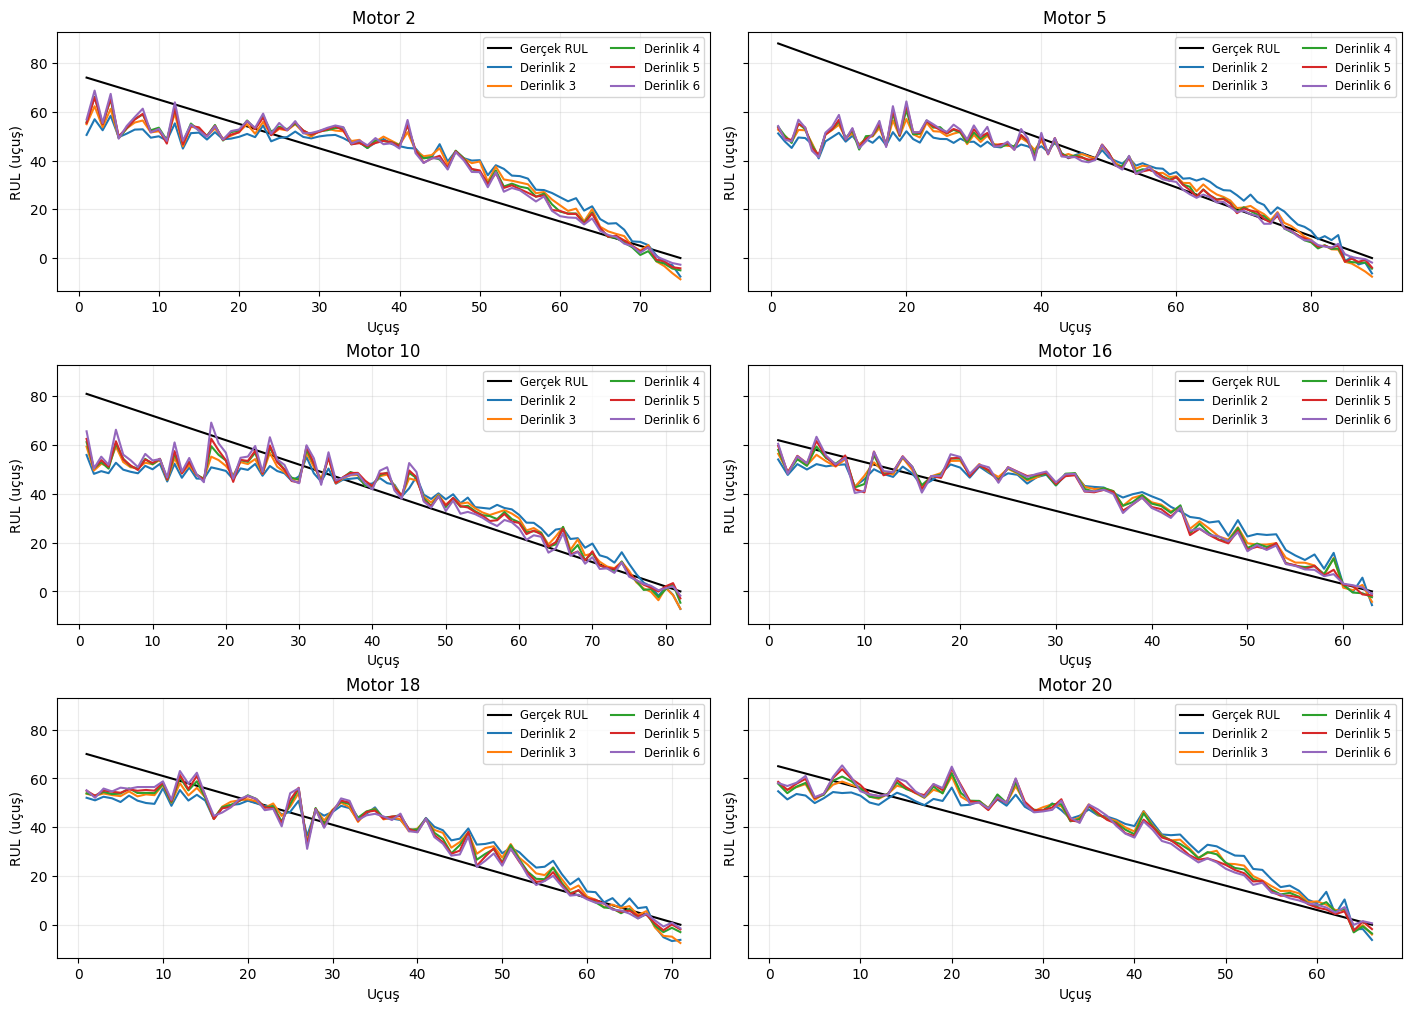

In [ ]:
prediction_fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey=True, layout="constrained")
for ax, (unit, flights) in zip(axes.flat, flight_predictions.groupby("unit")):
    ax.plot(flights["cycle"], flights["RUL"], label="Gerçek RUL", color="black")
    for depth in DEPTHS:
        column = prediction_column(depth)
        ax.plot(flights["cycle"], flights[column], label=column)
    ax.set(title=f"Motor {unit}", xlabel="Uçuş", ylabel="RUL (uçuş)")
    ax.grid(alpha=0.25)
    ax.legend(ncol=2, fontsize="small")
plt.show()

## Drive kaydı

In [ ]:
output_dir.mkdir(parents=True, exist_ok=True)
flight_predictions.to_csv(output_dir / "ucus_tahminleri.csv", index=False, encoding="utf-8-sig")
metrics.to_csv(output_dir / "derinlik_metrikleri.csv", index=False, encoding="utf-8-sig")
negative_counts.to_csv(output_dir / "negatif_tahmin_sayilari.csv", index=False, encoding="utf-8-sig")
prediction_fig.savefig(output_dir / "motor_tahminleri.png", dpi=150)
print(output_dir)

/content/drive/MyDrive/ncmapss/deneyler/xgboost_v03_agac_derinligi
